# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piasa19/flyrank-ml-internship-starter/blob/main/work/notebooks/capstone.ipynb)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

### Research Question

Which content pages should be prioritized for review or refresh based on their performance signals?

The main objective of this project is to identify content pages that may need improvement, monitoring, or updating.

The system will generate a ranked list of content pages based on available performance signals.

The unit of analysis is an individual content page. A FlyRank editor can use these recommendations to decide which pages should be reviewed first.

This approach helps organize large amounts of content data and supports better editorial decisions. The recommendations are decision-support signals, not guaranteed predictions of future performance.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

### Data Description

This project uses the FlyRank Internship Warehouse dataset.

- **Dataset:** FlyRank/internship-warehouse
- **Table:** fact_content_daily_performance_sample.parquet
- **Date range:** 1 June 2026 to 30 June 2026
- **Total records:** 11,694,072
- **Unique clients:** 65
- **Unique content items:** 409,205

The dataset contains Google Search Console (GSC) and Google Analytics 4 (GA4) performance measurements.

**Selected fields:**
- GSC impressions and clicks
- GSC average position
- GA4 pageviews
- GSC and GA4 data availability flags

**Excluded fields:**

Future-window metrics, trend_direction, trend_pct, raw URLs, raw queries and client-identifying information were excluded to reduce leakage and protect privacy.

Client and content hash IDs are used only for grouping and validation, not as model features.

**Data Limitations:**

The available sample covers only one month. Therefore, it cannot support a complete 90-day historical feature window followed by a 30-day target window.

Some GSC and GA4 measurements are missing or unavailable. The dataset also contains duplicate combinations of date, client ID and content ID.

These limitations are considered during the analysis.

In [ ]:
!pip -q install huggingface_hub pandas pyarrow

from huggingface_hub import hf_hub_download
import pandas as pd
import getpass

# Enter Hugging Face READ token
hf_token = getpass.getpass("Enter your Hugging Face READ token: ")

# Download dataset
file_path = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="fact_content_daily_performance_sample.parquet",
    repo_type="dataset",
    token=hf_token
)

# Load dataset
df = pd.read_parquet(file_path)

print("Dataset loaded successfully!")
print("Total rows:", len(df))

Enter your Hugging Face READ token: ··········
Dataset loaded successfully!
Total rows: 11694072


In [ ]:
# Section 2: Data Overview

print("Total Rows:", len(df))
print("Unique Clients:", df["client_hash_id"].nunique())
print("Unique Content Items:", df["content_hash_id"].nunique())

print("\nDate Range:")
print(df["report_date"].min(), "to", df["report_date"].max())

print("\nMissing Values:")
display(df[[
    "gsc_impressions",
    "gsc_clicks",
    "gsc_avg_position",
    "ga4_pageviews"
]].isnull().sum())

print("\nData Availability:")
print(df["gsc_data_available"].value_counts())
print(df["ga4_data_available"].value_counts(dropna=False))

Total Rows: 11694072
Unique Clients: 65
Unique Content Items: 409205

Date Range:
2026-06-01 to 2026-06-30

Missing Values:


,0
gsc_impressions,0
gsc_clicks,0
gsc_avg_position,7815170
ga4_pageviews,2397428



Data Availability:
gsc_data_available
False    7815135
True     3878937
Name: count, dtype: int64
ga4_data_available
False    8651918
None     2397428
True      644726
Name: count, dtype: int64


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

### Methodology

This project uses a Random Forest Classifier to identify content pages that may need a refresh.

**1. Target Definition**

The target variable is `needs_refresh`. It is created using the comparison between clicks in the last 30 days and the previous 30 days. It is a proxy label, not a confirmed refresh outcome.

**2. Features**

The model uses numerical performance features such as clicks, impressions, CTR, sessions, pageviews and content activity.

**3. Baseline and Model**

The Week-5 model is compared with a cleaned version of the same Random Forest model. The model uses 300 trees and a random seed of 42.

**4. Validation**

Three experiments are compared:
- Random split with the original Week-5 features.
- Grouped-by-client split with the original features.
- Grouped-by-client split after removing label-derived features.

**5. Leakage Checks**

Columns used to create the target, including `clicks_last_30d`, `clicks_prev_30d` and `trend_pct`, are removed from the cleaned feature set.

**6. Evaluation Metrics**

ROC AUC and Precision@50 are used to evaluate model performance.

The grouped split with cleaned features provides a more cautious estimate of performance on unseen clients.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

### Results

The Random Forest model was evaluated using three different validation experiments.

| Experiment | ROC AUC | Precision@50 |
|---|---:|---:|
| Random split with original features | 0.997 | 1.000 |
| Grouped-by-client split with original features | 0.997 | 1.000 |
| Grouped-by-client split with cleaned features | 0.903 | 0.928 |

**Key Findings:**

1. The original model achieved very high scores in both random and grouped validation.
2. After removing label-derived features, ROC AUC decreased to 0.903 and Precision@50 became 0.928.
3. This suggests that some original features were closely related to the target label and may have caused data leakage.
4. The cleaned model provides a more cautious estimate of performance.

**Conclusion:**

The cleaned Random Forest model shows promising results for identifying content pages that may need attention. However, the target is a proxy label, so the results should be treated as directional decision-support signals rather than guaranteed predictions.

,Experiment,ROC AUC,Precision@50
0,Random Split - Original Features,0.997,1.000
1,Grouped Split - Original Features,0.997,1.000
2,Grouped Split - Cleaned Features,0.903,0.928


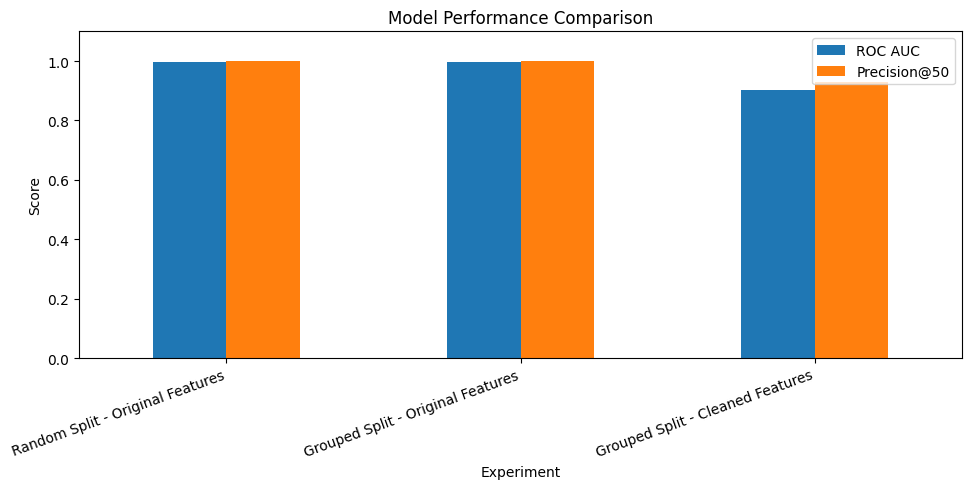

In [ ]:
# Section 4: Model Results

import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Experiment": [
        "Random Split - Original Features",
        "Grouped Split - Original Features",
        "Grouped Split - Cleaned Features"
    ],
    "ROC AUC": [0.997, 0.997, 0.903],
    "Precision@50": [1.000, 1.000, 0.928]
})

display(results)

# Visual comparison
results.set_index("Experiment").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 5. Limitations

*What this work cannot claim.*

### Limitations

Although the model shows promising results, there are some important limitations.

1. **Proxy Label:** The target `needs_refresh` is based on the comparison between clicks in the last 30 days and the previous 30 days. It does not represent a confirmed content refresh outcome.

2. **Limited Client Groups:** The validation dataset contains 30,000 rows from 32 client groups. Therefore, the results may not represent all clients.

3. **Feature Leakage:** The original model achieved very high scores. After removing label-derived features, ROC AUC decreased to 0.903 and Precision@50 decreased to 0.928. This shows why leakage checks are important.

4. **Time-Based Validation:** The evaluation used grouped-by-client validation. A separate time-aware validation was not performed.

5. **Window Overlap:** Some 90-day aggregate features still contain overlapping 30-day periods. Their influence needs further investigation.

6. **Model Errors:** The model produced both false positives and false negatives. Therefore, its recommendations should be reviewed by humans.

**Overall Limitation:**

This model is a decision-support tool for prioritizing content review. It does not guarantee that refreshing a page will improve its search performance.

In [ ]:
# Section 5: Limitations and Validation Evidence

limitations = pd.DataFrame({
    "Evidence": [
        "Rows in validation dataset",
        "Client groups",
        "Positive label rate",
        "Cleaned model mean ROC AUC",
        "Cleaned model ROC AUC standard deviation",
        "Cleaned model mean Precision@50",
        "Cleaned model Precision@50 standard deviation"
    ],
    "Value": [
        30000,
        32,
        0.227,
        0.903,
        0.050,
        0.928,
        0.030
    ]
})

display(limitations)

,Evidence,Value
0,Rows in validation dataset,30000.000
1,Client groups,32.000
2,Positive label rate,0.227
3,Cleaned model mean ROC AUC,0.903
4,Cleaned model ROC AUC standard deviation,0.050
5,Cleaned model mean Precision@50,0.928
6,Cleaned model Precision@50 standard deviation,0.030


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

### Ranked Recommendations

The model can be used to prioritize content pages for manual review based on their predicted `needs_refresh` scores.

The following actions are recommended:

1. **High-Priority Review:** Pages with higher model scores should be reviewed first by the editorial team.

2. **Check Click Performance:** Review pages where clicks have decreased compared with the previous 30-day period.

3. **Check Search Performance:** Examine impressions, CTR and average search position to understand possible performance issues.

4. **Check Data Availability:** Confirm that the required GSC and GA4 measurements are available before making decisions.

5. **Manual Verification:** Editors should review the content, search intent and available performance data before deciding whether a refresh is needed.

**Important Note:**

These recommendations are intended to support editorial decisions. The model score does not guarantee that a page needs updating or that refreshing it will improve performance. Human review is required before taking action.

In [ ]:
# Section 6: Ranked Recommendations

recommendations = pd.DataFrame({
    "Priority": [
        "High",
        "Medium",
        "Low"
    ],
    "Recommended Action": [
        "Review pages with high predicted needs_refresh scores",
        "Investigate pages with declining clicks or CTR",
        "Monitor pages with stable performance"
    ],
    "Action": [
        "Manual content review",
        "Check search performance and content quality",
        "Continue monitoring"
    ]
})

display(recommendations)

# Export recommendations
recommendations.to_csv(
    "ranked_recommendations.csv",
    index=False
)

print("Recommendations exported successfully!")

,Priority,Recommended Action,Action
0,High,Review pages with high predicted needs_refresh...,Manual content review
1,Medium,Investigate pages with declining clicks or CTR,Check search performance and content quality
2,Low,Monitor pages with stable performance,Continue monitoring


Recommendations exported successfully!


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

### Artifacts the Paper Embeds

The final research paper will include the following supporting materials:

1. **Model Performance Table:** A comparison of ROC AUC and Precision@50 across the three validation experiments.
2. **Performance Comparison Chart:** A bar chart showing the performance of the original and cleaned models.
3. **Validation Evidence:** Results from grouped-by-client validation, including the cleaned model's mean scores and standard deviations.
4. **Limitations:** A summary of data limitations, possible feature leakage and model errors.

These artifacts provide supporting evidence for the methodology, results and conclusions of the project.

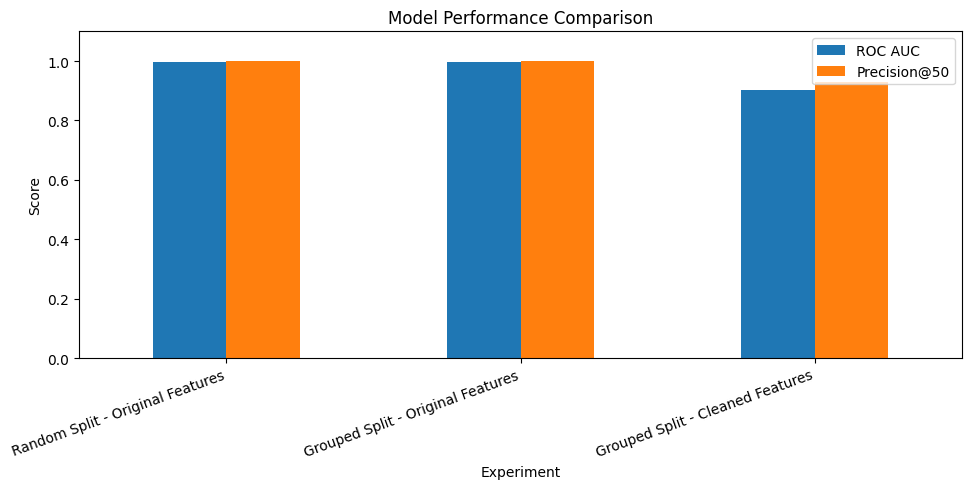

Artifacts exported successfully!
1. model_performance_results.csv
2. validation_evidence.csv
3. model_performance_chart.png


In [ ]:
# Section 7: Export Artifacts for the Final Paper

import matplotlib.pyplot as plt

# 1. Export model performance table
results.to_csv("model_performance_results.csv", index=False)

# 2. Export validation evidence
limitations.to_csv("validation_evidence.csv", index=False)

# 3. Save model performance chart
results.set_index("Experiment").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig("model_performance_chart.png", dpi=300, bbox_inches="tight")
plt.show()

print("Artifacts exported successfully!")
print("1. model_performance_results.csv")
print("2. validation_evidence.csv")
print("3. model_performance_chart.png")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

In [ ]:
# Section 8: Final Self-Check

checks = {
    "Research question defined": True,
    "Dataset documented": True,
    "Methodology explained": True,
    "Model evaluation completed": True,
    "Leakage checks performed": True,
    "Limitations documented": True,
    "Recommendations included": True,
    "Supporting charts and tables prepared": True
}

for item, status in checks.items():
    print(("✓" if status else "✗"), item)

print("\nSelf-check completed.")

✓ Research question defined
✓ Dataset documented
✓ Methodology explained
✓ Model evaluation completed
✓ Leakage checks performed
✓ Limitations documented
✓ Recommendations included
✓ Supporting charts and tables prepared

Self-check completed.


## 9. Five-Minute Demo Outline

### 1. Problem (30 seconds)
Explain the problem of identifying which content pages should be reviewed or refreshed first.

### 2. Research Question (45 seconds)
Which content pages should be prioritized using available search and analytics performance signals?

### 3. Methodology (1 minute)
- Used anonymized FlyRank data.
- Performed data cleaning and feature selection.
- Developed a rule-based baseline.
- Built a Random Forest classifier.
- Considered data leakage and grouped validation.

### 4. Results (1 minute)
Present the model performance chart.

Recorded model results:
- ROC AUC: 0.903
- Precision@50: 0.928

### 5. Key Finding (1 minute)
The model showed promising results, but the proxy target and possible data limitations must be considered.

### 6. Recommendation (45 seconds)
Use the model's priority ranking to help editors identify pages for manual review before making content refresh decisions.

## 10. Sharing the Project

### Social Media Post

I recently completed my Machine Learning capstone project on Content Refresh Prioritization.

Using anonymized FlyRank search and analytics data, I explored how machine learning can help identify content pages that may require review or refreshing.

I developed a Random Forest classifier and explored data leakage prevention and grouped validation.

One of my biggest learnings was understanding why proper validation and feature selection are important for building reliable machine learning models.

This project helped me connect machine learning concepts with a practical content management problem.

### Employer-Facing Summary

I developed a machine learning-based content refresh prioritization system using anonymized FlyRank search and analytics data. I built a Random Forest classifier and evaluated it while considering feature leakage and grouped-by-client validation. The model achieved a recorded ROC AUC of 0.903 and Precision@50 of 0.928, showing potential for supporting human-led content review decisions.